# Final Project
Afonso Cordeiro - 2021225966\
Tomás Clemente - 2021232197

## Part 1

#### Imports



In [1]:
!pip install pgmpy

In [2]:
import os
import pandas as pd
import numpy as np
from pgmpy.estimators import BDeuScore, K2Score, BicScore, HillClimbSearch
from sklearn.preprocessing import LabelEncoder
import networkx as nx
import matplotlib.pyplot as plt
from pgmpy.models import BayesianModel
from pgmpy.estimators import MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination

########################### VAE ####################################

import tensorflow as tf
from tensorflow.keras.datasets import mnist

from tensorflow.keras.layers import Input, Conv2D, Flatten, Dense, Conv2DTranspose, Reshape, Lambda, Activation, LeakyReLU
from tensorflow.keras.models import Model
from tensorflow.keras import backend as K
from tensorflow.keras.optimizers.legacy import Adam

import numpy as np
import math

from tensorflow.keras.callbacks import Callback,LearningRateScheduler
import matplotlib.pyplot as plt

tf.compat.v1.disable_eager_execution()

c:\Users\tomas\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



#### Load Dataset

In [99]:
df = pd.read_csv('Dataset_1/imdb_movies.csv')

In [4]:
df

,names,date_x,score,genre,overview,crew,orig_title,status,orig_lang,budget_x,revenue,country
0,Creed III,03/02/2023,73.0,"Drama, Action","After dominating the boxing world, Adonis Cree...","Michael B. Jordan, Adonis Creed, Tessa Thompso...",Creed III,Released,English,75000000.0,2.716167e+08,AU
1,Avatar: The Way of Water,12/15/2022,78.0,"Science Fiction, Adventure, Action",Set more than a decade after the events of the...,"Sam Worthington, Jake Sully, Zoe Saldaña, Neyt...",Avatar: The Way of Water,Released,English,460000000.0,2.316795e+09,AU
2,The Super Mario Bros. Movie,04/05/2023,76.0,"Animation, Adventure, Family, Fantasy, Comedy","While working underground to fix a water main,...","Chris Pratt, Mario (voice), Anya Taylor-Joy, P...",The Super Mario Bros. Movie,Released,English,100000000.0,7.244590e+08,AU
3,Mummies,01/05/2023,70.0,"Animation, Comedy, Family, Adventure, Fantasy","Through a series of unfortunate events, three ...","Óscar Barberán, Thut (voice), Ana Esther Albor...",Momias,Released,"Spanish, Castilian",12300000.0,3.420000e+07,AU
4,Supercell,03/17/2023,61.0,Action,Good-hearted teenager William always lived in ...,"Skeet Ulrich, Roy Cameron, Anne Heche, Dr Quin...",Supercell,Released,English,77000000.0,3.409420e+08,US
...,...,...,...,...,...,...,...,...,...,...,...,...
10173,20th Century Women,12/28/2016,73.0,Drama,"In 1979 Santa Barbara, California, Dorothea Fi...","Annette Bening, Dorothea Fields, Lucas Jade Zu...",20th Century Women,Released,English,7000000.0,9.353729e+06,US
10174,Delta Force 2: The Colombian Connection,08/24/1990,54.0,Action,When DEA agents are taken captive by a ruthles...,"Chuck Norris, Col. Scott McCoy, Billy Drago, R...",Delta Force 2: The Colombian Connection,Released,English,9145817.8,6.698361e+06,US
10175,The Russia House,12/21/1990,61.0,"Drama, Thriller, Romance","Barley Scott Blair, a Lisbon-based editor of R...","Sean Connery, Bartholomew 'Barley' Scott Blair...",The Russia House,Released,English,21800000.0,2.299799e+07,US
10176,Darkman II: The Return of Durant,07/11/1995,55.0,"Action, Adventure, Science Fiction, Thriller, ...",Darkman and Durant return and they hate each o...,"Larry Drake, Robert G. Durant, Arnold Vosloo, ...",Darkman II: The Return of Durant,Released,English,116000000.0,4.756613e+08,US


#### Df analysis

In [5]:
#column to list
df.columns.tolist()

['names',
 'date_x',
 'score',
 'genre',
 'overview',
 'crew',
 'orig_title',
 'status',
 'orig_lang',
 'budget_x',
 'revenue',
 'country']

In [6]:
#data information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10178 entries, 0 to 10177
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   names       10178 non-null  object 
 1   date_x      10178 non-null  object 
 2   score       10178 non-null  float64
 3   genre       10093 non-null  object 
 4   overview    10178 non-null  object 
 5   crew        10122 non-null  object 
 6   orig_title  10178 non-null  object 
 7   status      10178 non-null  object 
 8   orig_lang   10178 non-null  object 
 9   budget_x    10178 non-null  float64
 10  revenue     10178 non-null  float64
 11  country     10178 non-null  object 
dtypes: float64(3), object(9)
memory usage: 954.3+ KB


In [7]:
#describing the data
df.describe()

,score,budget_x,revenue
count,10178.000000,1.017800e+04,1.017800e+04
mean,63.497052,6.488238e+07,2.531401e+08
std,13.537012,5.707565e+07,2.777880e+08
min,0.000000,1.000000e+00,0.000000e+00
25%,59.000000,1.500000e+07,2.858898e+07
50%,65.000000,5.000000e+07,1.529349e+08
75%,71.000000,1.050000e+08,4.178021e+08
max,100.000000,4.600000e+08,2.923706e+09


In [8]:
# check for missing values:
df.isnull().sum()

names          0
date_x         0
score          0
genre         85
overview       0
crew          56
orig_title     0
status         0
orig_lang      0
budget_x       0
revenue        0
country        0
dtype: int64

In [9]:
#checking duplicate values
df.nunique()

names         9660
date_x        5688
score           79
genre         2303
overview      9905
crew          9927
orig_title    9736
status           3
orig_lang       54
budget_x      2316
revenue       8227
country         60
dtype: int64

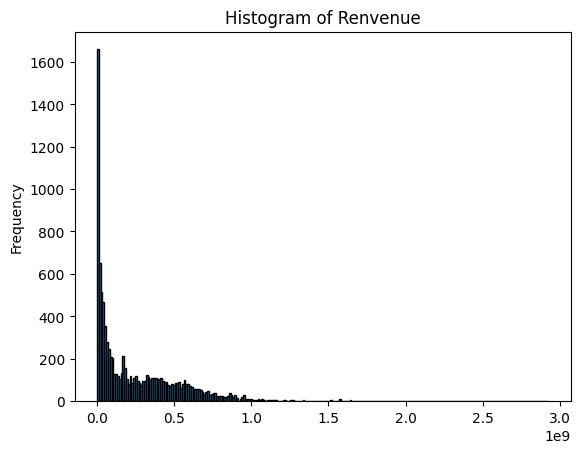

In [80]:
plt.hist(df.revenue, bins=250, edgecolor='black')
plt.ylabel('Frequency')
plt.title('Histogram of Renvenue')
plt.show()

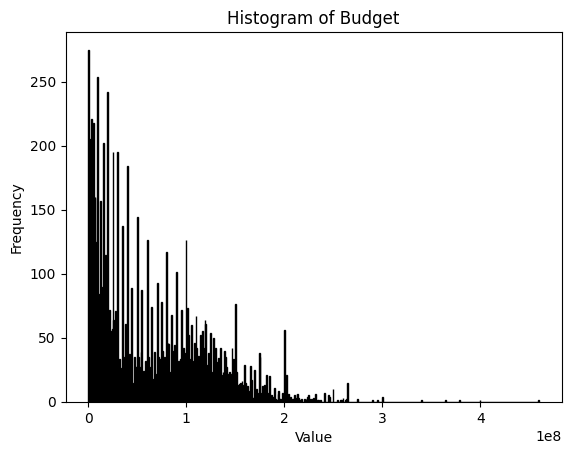

In [79]:
plt.hist(df.budget_x, bins=500, edgecolor='black')  # Adjust the number of bins as needed
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Histogram of Budget')
plt.show()

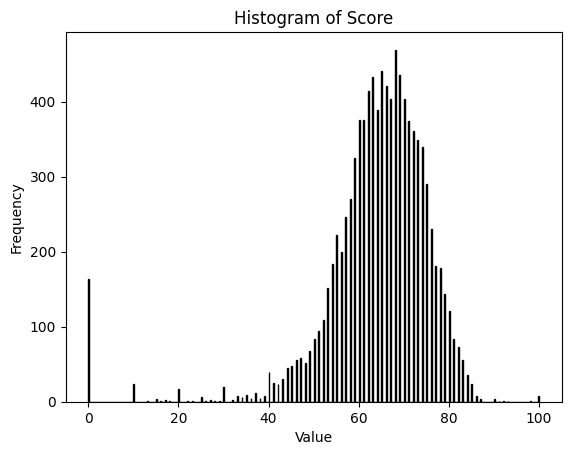

In [78]:
plt.hist(df.score, bins=500, edgecolor='black')  # Adjust the number of bins as needed
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Histogram of Score')
plt.show()

#### Pre Processamento

In [100]:
#removing data values
df = df.drop(np.where(df["crew"].isnull())[0])
df = df.reset_index()

df = df.drop(np.where(df["genre"].isnull())[0])
df = df.reset_index()

df = df.drop(['level_0', 'index'], axis=1)

In [101]:
encoder = LabelEncoder()
df.status = encoder.fit_transform(df.status)
status_mapping = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))

df.country = encoder.fit_transform(df.country)
country_mapping = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))

df.orig_lang = encoder.fit_transform(df.orig_lang)

In [102]:
for i in range(len(df.genre)):
  df.genre[i] = df.loc[i, 'genre'].replace("\xa0", "").split(",")

for i in range(len(df.date_x)):
  df.date_x[i] = df.loc[i, 'date_x'].split("/")

In [103]:
generos =  ['Action', 'Adventure', 'Animation','Comedy','Crime','Documentary','Drama','Family','Fantasy','History','Horror','Music','Mystery','Romance','Science Fiction','TV Movie','Thriller','War','Western']
data = ["Mes","Ano"]
for i in generos:
  df[i] = np.zeros((len(df))).astype(int)

for i in range(len(df.genre)):
  for j in df.genre[i]:
    df.loc[i, j] = 1

for i in data:
  df[i] = np.zeros((len(df))).astype(int)

for i in range(len(df.date_x)):
  df.loc[i, 'Mes'] = df.date_x[i][0]
  df.loc[i, 'Ano'] = df.date_x[i][2]


df = df.drop(["date_x","genre","names","crew","orig_title","overview"],axis=1)

df["score"] = pd.cut(df['score'], bins=[0,40,80,100], labels=[i for i in range(3)], include_lowest=True)

C:\Users\tomas\AppData\Local\Temp\ipykernel_408\1982126861.py:14: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '03' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  df.loc[i, 'Mes'] = df.date_x[i][0]
C:\Users\tomas\AppData\Local\Temp\ipykernel_408\1982126861.py:15: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '2023 ' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  df.loc[i, 'Ano'] = df.date_x[i][2]


In [104]:
for i in range(len(df["budget_x"])):
  if df["budget_x"][i] <= 0.4e8:
    df.loc[i,'budget_x'] = 0
  elif df["budget_x"][i] > 0.4e8 and df["budget_x"][i] <= 1e8:
    df.loc[i,'budget_x'] = 1
  elif df["budget_x"][i] > 1e8 and df["budget_x"][i] <= 1.5e8:
    df.loc[i,'budget_x'] = 2
  elif df["budget_x"][i] > 1.5e8 and df["budget_x"][i] <= 2.1e8:
    df.loc[i,'budget_x'] = 3
  else:
    df.loc[i,'budget_x'] = 4


for i in range(len(df["revenue"])):
  if df["revenue"][i] <= 0.15e9:
    df.loc[i,'revenue'] = 0
  elif df["revenue"][i] > 0.15e9 and df["revenue"][i] <= 0.25e9:
    df.loc[i,'revenue'] = 1
  elif df["revenue"][i] > 0.25e9 and df["revenue"][i] <= 0.6e9:
    df.loc[i,'revenue'] = 2
  elif df["revenue"][i] > 0.6e9 and df["revenue"][i] <= 0.8e9:
    df.loc[i,'revenue'] = 3
  else:
    df.loc[i,'revenue'] = 4

df = df.astype({'score':'int'})
df = df.astype({'budget_x':'int'})
df = df.astype({'revenue':'int'})

In [18]:
df

,score,status,orig_lang,budget_x,revenue,country,Action,Adventure,Animation,Comedy,...,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western,Mes,Ano
0,1,2,12,1,3,2,1,0,0,0,...,0,0,0,0,0,0,0,0,03,2023
1,1,2,12,4,4,2,1,1,0,0,...,0,0,0,1,0,0,0,0,12,2022
2,1,2,12,1,4,2,0,1,1,1,...,0,0,0,0,0,0,0,0,04,2023
3,1,2,44,0,0,2,0,1,1,1,...,0,0,0,0,0,0,0,0,01,2023
4,1,2,12,1,3,52,1,0,0,0,...,0,0,0,0,0,0,0,0,03,2023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10047,1,2,12,0,0,52,0,0,0,0,...,0,0,0,0,0,0,0,0,12,2016
10048,1,2,12,0,0,52,1,0,0,0,...,0,0,0,0,0,0,0,0,08,1990
10049,1,2,12,0,0,52,0,0,0,0,...,0,0,1,0,0,1,0,0,12,1990
10050,1,2,12,2,3,52,1,1,0,0,...,0,0,0,1,0,1,0,0,07,1995


#### Estrutura da Bayes Net

In [105]:
bdeu = BDeuScore(df, equivalent_sample_size=5)
k2 = K2Score(df)
bic = BicScore(df)

hc = HillClimbSearch(df)

model0 = hc.estimate(scoring_method=bdeu)
model1 = hc.estimate(scoring_method=k2)
model2 = hc.estimate(bic)

print("BDeu Score:",BDeuScore(df, equivalent_sample_size=5).score(model0))
print("K2 Score;", K2Score(df).score(model1))
print("Bic Score:",BicScore(df).score(model2))

  0%|          | 8/1000000 [00:04<150:43:09,  1.84it/s]c:\Users\tomas\AppData\Local\Programs\Python\Python310\lib\site-packages\pgmpy\estimators\StructureScore.py:136: RuntimeWarning: overflow encountered in scalar multiply
  (num_parents_states - counts.shape[1]) * var_cardinality * gammaln(1)
c:\Users\tomas\AppData\Local\Programs\Python\Python310\lib\site-packages\pgmpy\estimators\StructureScore.py:136: RuntimeWarning: overflow encountered in scalar multiply
  (num_parents_states - counts.shape[1]) * var_cardinality * gammaln(1)
c:\Users\tomas\AppData\Local\Programs\Python\Python310\lib\site-packages\pgmpy\estimators\StructureScore.py:136: RuntimeWarning: overflow encountered in scalar multiply
  (num_parents_states - counts.shape[1]) * var_cardinality * gammaln(1)
c:\Users\tomas\AppData\Local\Programs\Python\Python310\lib\site-packages\pgmpy\estimators\StructureScore.py:136: RuntimeWarning: overflow encountered in scalar multiply
  (num_parents_states - counts.shape[1]) * var_cardin

BDeu Score: -166345.7592899579
K2 Score; 769454581479.9077


c:\Users\tomas\AppData\Local\Programs\Python\Python310\lib\site-packages\pgmpy\estimators\StructureScore.py:136: RuntimeWarning: overflow encountered in scalar multiply
  (num_parents_states - counts.shape[1]) * var_cardinality * gammaln(1)


Bic Score: -175434.6111332681


In [106]:
print(model1.edges())
print(model1)
print(model1.nodes())

relations = model1.edges()

[('score', 'country'), ('score', 'revenue'), ('score', 'budget_x'), ('score', 'Ano'), ('status', 'country'), ('status', 'revenue'), ('status', 'budget_x'), ('status', 'Ano'), ('status', 'score'), ('status', 'Mes'), ('orig_lang', 'country'), ('orig_lang', 'Animation'), ('orig_lang', 'revenue'), ('orig_lang', 'budget_x'), ('orig_lang', 'Action'), ('orig_lang', 'Ano'), ('orig_lang', 'score'), ('orig_lang', 'Romance'), ('orig_lang', 'Comedy'), ('orig_lang', 'Mes'), ('orig_lang', 'Family'), ('budget_x', 'country'), ('budget_x', 'Ano'), ('budget_x', 'Mes'), ('budget_x', 'revenue'), ('revenue', 'country'), ('revenue', 'Ano'), ('revenue', 'Mes'), ('Action', 'Adventure'), ('Action', 'Drama'), ('Action', 'Science Fiction'), ('Action', 'Horror'), ('Action', 'revenue'), ('Action', 'score'), ('Action', 'Mystery'), ('Action', 'Mes'), ('Action', 'budget_x'), ('Action', 'Music'), ('Action', 'Comedy'), ('Action', 'Thriller'), ('Action', 'War'), ('Action', 'Documentary'), ('Adventure', 'Fantasy'), ('Adv

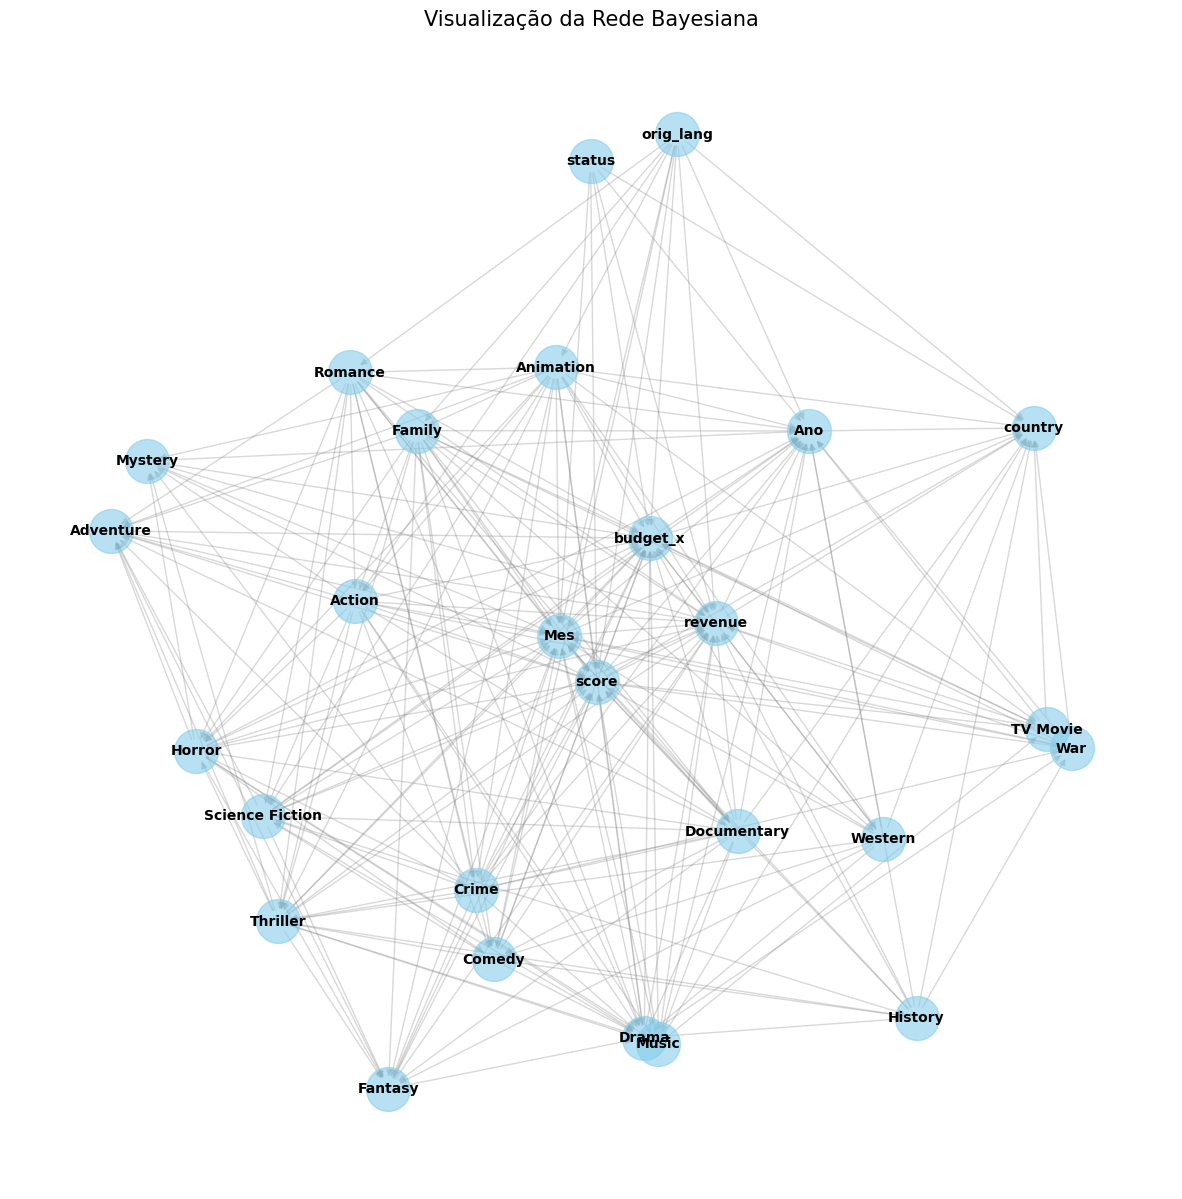

In [107]:
G = nx.DiGraph()
G.add_edges_from(model1.edges())
pos = nx.kamada_kawai_layout(G, scale=30)


plt.figure(figsize=(15, 15))
edges = nx.draw_networkx_edges(G, pos, arrowstyle='-|>', arrowsize=10, edge_color='gray', width=1, alpha=0.3)
nodes = nx.draw_networkx_nodes(G, pos, node_size=1000, node_color='skyblue', alpha=0.6)
labels = nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

plt.title('Visualização da Rede Bayesiana', fontsize=15)
plt.axis('off')
plt.show()

In [108]:
for i in range(len(df)):
    if df.loc[i, "Crime"] == 1 or df.loc[i,"Mystery"] == 1 or df.loc[i,"Romance"] == 1:
        df.loc[i,"Cluster_CMR"] = 1
    else: 
        df.loc[i,"Cluster_CMR"] = 0

    if df.loc[i, "Action"] == 1 or df.loc[i,"Science Fiction"] == 1 or df.loc[i,"Adventure"] == 1:
        df.loc[i,"Cluster_ASA"] = 1
    else:
        df.loc[i,"Cluster_ASA"] = 0

    if df.loc[i,"Documentary"] == 1 or df.loc[i,"History"] == 1 or df.loc[i,"War"] == 1 or df.loc[i,"Western"] == 1:
        df.loc[i,"Cluster_DHWW"] = 1
    else:
        df.loc[i,"Cluster_DHWW"] = 0

    if df.loc[i,"Horror"] == 1 or df.loc[i,"Thriller"] == 1 or df.loc[i,"Drama"] == 1:
        df.loc[i,"Cluster_HTD"] = 1
    else:
        df.loc[i,"Cluster_HTD"] = 0

    if df.loc[i,"Fantasy"] == 1 or df.loc[i,"Family"] == 1 or df.loc[i,"Animation"] == 1 or df.loc[i,"TV Movie"] == 1 or df.loc[i,"Comedy"] == 1 or df.loc[i,"Music"] == 1:
        df.loc[i,"Cluster_FFATCM"] = 1
    else:
        df.loc[i,"Cluster_FFATCM"] = 0

df = df.astype({'Cluster_CMR':'int'})
df = df.astype({"Cluster_ASA":'int'})
df = df.astype({"Cluster_DHWW":'int'})
df = df.astype({"Cluster_HTD":'int'})
df = df.astype({"Cluster_FFATCM":'int'})

In [109]:
df = df.drop(['Mes','Ano','orig_lang','Action', 'Adventure', 'Animation','Comedy','Crime','Documentary','Drama','Family','Fantasy','History','Horror','Music','Mystery','Romance','Science Fiction','TV Movie','Thriller','War','Western'], axis=1)

In [110]:
bdeu = BDeuScore(df, equivalent_sample_size=5)
k2 = K2Score(df)
bic = BicScore(df)

hc = HillClimbSearch(df)

model3 = hc.estimate(scoring_method=bdeu)
model4 = hc.estimate(scoring_method=k2)
model5 = hc.estimate(bic)

print("BDeu Score:",BDeuScore(df, equivalent_sample_size=5).score(model3))
print("K2 Score:", K2Score(df).score(model4))
print("Bic Score:",BicScore(df).score(model5))

  0%|          | 0/1000000 [00:00<?, ?it/s]

  0%|          | 17/1000000 [00:00<6:59:10, 39.76it/s]


BDeu Score: -69036.01319708787
K2 Score: 239322.01110310195
Bic Score: -69492.63702471921


In [111]:
best_model = model4

print(best_model.edges())
print(best_model)
print(best_model.nodes())

relations = list(best_model.edges())

[('score', 'revenue'), ('score', 'budget_x'), ('status', 'revenue'), ('status', 'budget_x'), ('status', 'score'), ('status', 'Cluster_ASA'), ('budget_x', 'revenue'), ('country', 'revenue'), ('country', 'budget_x'), ('country', 'Cluster_ASA'), ('country', 'score'), ('country', 'Cluster_FFATCM'), ('country', 'Cluster_HTD'), ('Cluster_CMR', 'revenue'), ('Cluster_CMR', 'budget_x'), ('Cluster_CMR', 'score'), ('Cluster_ASA', 'revenue'), ('Cluster_ASA', 'budget_x'), ('Cluster_ASA', 'Cluster_HTD'), ('Cluster_ASA', 'Cluster_CMR'), ('Cluster_ASA', 'Cluster_FFATCM'), ('Cluster_ASA', 'score'), ('Cluster_ASA', 'Cluster_DHWW'), ('Cluster_DHWW', 'revenue'), ('Cluster_DHWW', 'budget_x'), ('Cluster_DHWW', 'Cluster_FFATCM'), ('Cluster_DHWW', 'Cluster_CMR'), ('Cluster_DHWW', 'score'), ('Cluster_DHWW', 'Cluster_HTD'), ('Cluster_HTD', 'Cluster_FFATCM'), ('Cluster_HTD', 'revenue'), ('Cluster_HTD', 'budget_x'), ('Cluster_HTD', 'Cluster_CMR'), ('Cluster_HTD', 'score'), ('Cluster_FFATCM', 'revenue'), ('Cluster

In [112]:
relations.append(('country', 'Cluster_CMR'))
relations.append(('country', 'Cluster_DHWW'))
to_remove = [('status', 'Cluster_ASA'), ('Cluster_DHWW', 'Cluster_FFATCM'), ('Cluster_DHWW', 'Cluster_CMR'), ('Cluster_DHWW', 'Cluster_HTD'), ('Cluster_HTD', 'Cluster_FFATCM'), ('Cluster_HTD', 'Cluster_CMR')]

relations = [x for x in relations if x not in to_remove]

In [113]:
model = BayesianModel(relations)

model.fit(df, estimator=MaximumLikelihoodEstimator)

In [114]:
print('\nMLE - CPDs Aprendidas:')
for cpd in model.get_cpds():
    print(cpd)


MLE - CPDs Aprendidas:
+----------------+-----+--------------------+
| Cluster_ASA    | ... | Cluster_ASA(1)     |
+----------------+-----+--------------------+
| Cluster_CMR    | ... | Cluster_CMR(1)     |
+----------------+-----+--------------------+
| Cluster_DHWW   | ... | Cluster_DHWW(1)    |
+----------------+-----+--------------------+
| Cluster_FFATCM | ... | Cluster_FFATCM(1)  |
+----------------+-----+--------------------+
| Cluster_HTD    | ... | Cluster_HTD(1)     |
+----------------+-----+--------------------+
| country        | ... | country(56)        |
+----------------+-----+--------------------+
| status         | ... | status(2)          |
+----------------+-----+--------------------+
| score(0)       | ... | 0.3333333333333333 |
+----------------+-----+--------------------+
| score(1)       | ... | 0.3333333333333333 |
+----------------+-----+--------------------+
| score(2)       | ... | 0.3333333333333333 |
+----------------+-----+--------------------+
+---------

In [115]:
bdeu = BDeuScore(df, equivalent_sample_size=5)
k2 = K2Score(df)
bic = BicScore(df)

hc = HillClimbSearch(df)

print("BDeu Score:", BDeuScore(df, equivalent_sample_size=5).score(model))
print("K2 Score:", K2Score(df).score(model))
print("Bic Score:", BicScore(df).score(model))

-85356.88107387516
237161.3965051382
-1934122.8991998623


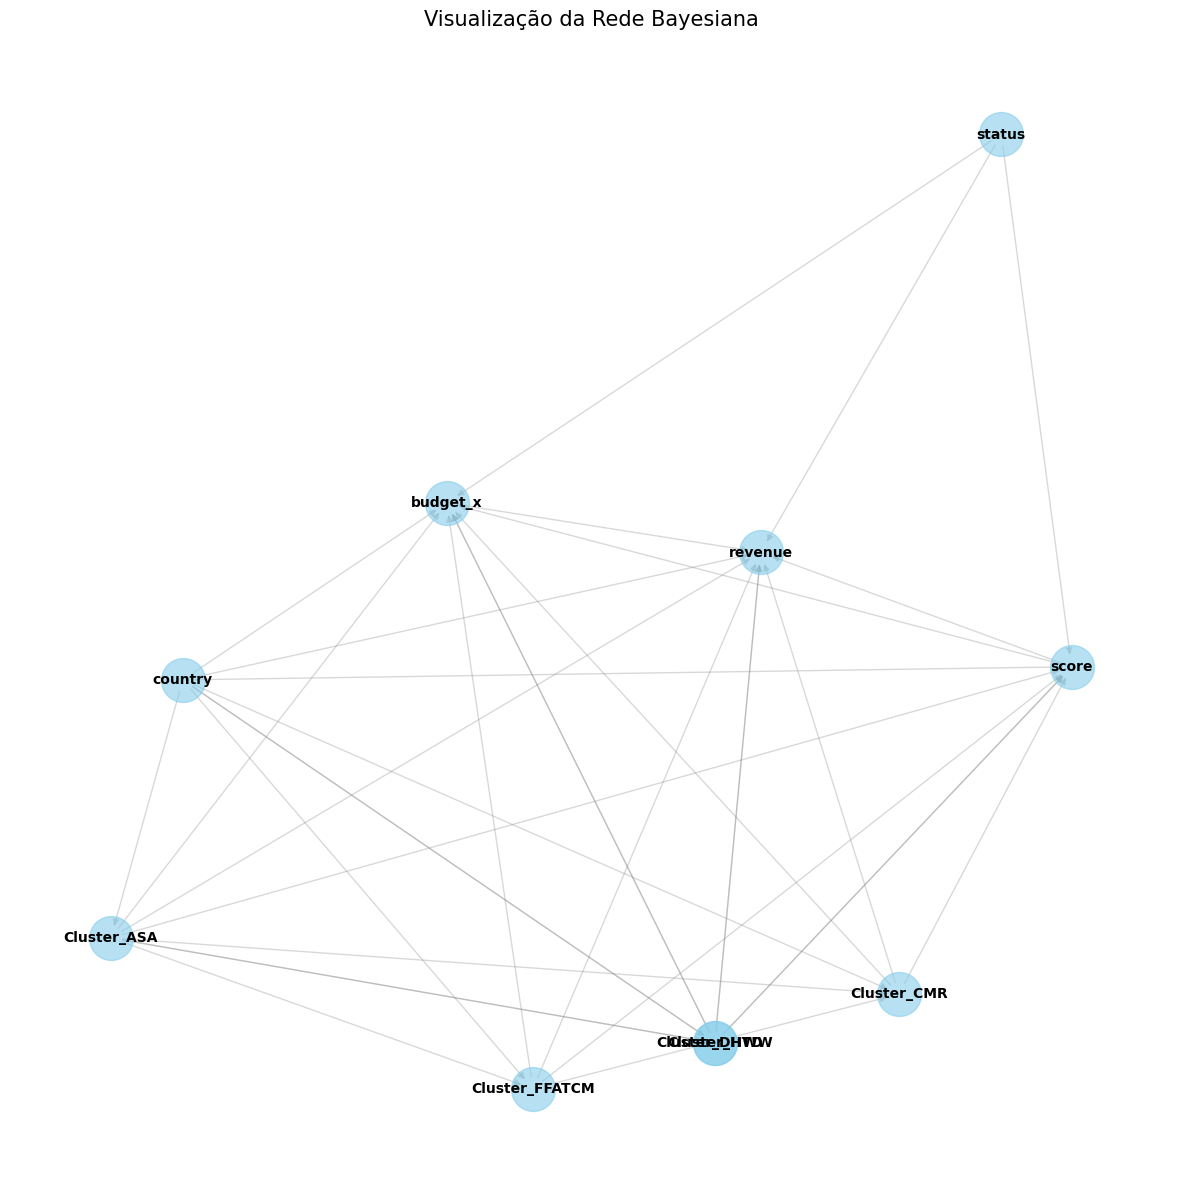

In [116]:
G = nx.DiGraph()
G.add_edges_from(model.edges())
pos = nx.kamada_kawai_layout(G, scale=30)


plt.figure(figsize=(15, 15))
edges = nx.draw_networkx_edges(G, pos, arrowstyle='-|>', arrowsize=10, edge_color='gray', width=1, alpha=0.3)
nodes = nx.draw_networkx_nodes(G, pos, node_size=1000, node_color='skyblue', alpha=0.6)
labels = nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

plt.title('Visualização da Rede Bayesiana', fontsize=15)
plt.axis('off')
plt.show()

#### Inferências

In [117]:
infer = VariableElimination(model)

print("\nBudget Dictionary:\n0:         0 - 40000000\n1:  40000000 - 100000000\n2: 100000000 - 150000000\n3: 150000000 - 210000000\n4: 210000000 - inf\n")

# Computing the probability of the range of a budget from a film
q = infer.query(variables=["budget_x"])
print(q,"\n")


Budget Dictionary:
0:         0 - 40000000
1:  40000000 - 100000000
2: 100000000 - 150000000
3: 150000000 - 210000000
4: 210000000 - inf

+-------------+-----------------+
| budget_x    |   phi(budget_x) |
+=============+=================+
| budget_x(0) |          0.4485 |
+-------------+-----------------+
| budget_x(1) |          0.2588 |
+-------------+-----------------+
| budget_x(2) |          0.1934 |
+-------------+-----------------+
| budget_x(3) |          0.0769 |
+-------------+-----------------+
| budget_x(4) |          0.0223 |
+-------------+-----------------+ 



In [121]:
print("\nBudget Dictionary:\n0:         0 - 150000000\n1: 150000000 - 250000000\n2: 250000000 - 600000000\n3: 600000000 - 800000000\n4: 800000000 - inf\n")

# Computing the probability of the range of a revenue from a film considering that budget is between 100000000 - 150000000, 
# with a score is between 40-80 and its status is in production 
q = infer.query(variables=["revenue"], evidence={"budget_x": 2, "score":1,"status":status_mapping[" In Production"]})
print(q,"\n")



Budget Dictionary:
0:         0 - 150000000
1: 150000000 - 250000000
2: 250000000 - 600000000
3: 600000000 - 800000000
4: 800000000 - inf

+------------+----------------+
| revenue    |   phi(revenue) |
+============+================+
| revenue(0) |         0.2000 |
+------------+----------------+
| revenue(1) |         0.2000 |
+------------+----------------+
| revenue(2) |         0.2000 |
+------------+----------------+
| revenue(3) |         0.2000 |
+------------+----------------+
| revenue(4) |         0.2000 |
+------------+----------------+ 



In [39]:
# Computing the probability of a film to be in the category of Action/Science Fiction/Adventure and in 
# the category of Crime/Mystery/Romance given that it is filmed in the USA
q = infer.query(variables=["Cluster_ASA", "Cluster_CMR"], evidence={"country": country_mapping["US"]}, joint=False)
for factor in q.values():
    print(factor)

+----------------+--------------------+
| Cluster_ASA    |   phi(Cluster_ASA) |
+================+====================+
| Cluster_ASA(0) |             0.6587 |
+----------------+--------------------+
| Cluster_ASA(1) |             0.3413 |
+----------------+--------------------+
+----------------+--------------------+
| Cluster_CMR    |   phi(Cluster_CMR) |
+================+====================+
| Cluster_CMR(0) |             0.7021 |
+----------------+--------------------+
| Cluster_CMR(1) |             0.2979 |
+----------------+--------------------+


In [45]:
# Computing the probability of a film inserted in the clusters Fantasy/Family/Animation/TV Movie/Comedy/Music and Horror/Thriller/Drama 
# at the same time given that it is filmed in UK and its score is between 80-100
q = infer.query(variables=["Cluster_FFATCM", "Cluster_HTD"], evidence={"country": country_mapping["GB"], "score":2})
print(q,"\n")

+-------------------+----------------+-----------------------------------+
| Cluster_FFATCM    | Cluster_HTD    |   phi(Cluster_FFATCM,Cluster_HTD) |
+===================+================+===================================+
| Cluster_FFATCM(0) | Cluster_HTD(0) |                            0.5972 |
+-------------------+----------------+-----------------------------------+
| Cluster_FFATCM(0) | Cluster_HTD(1) |                            0.0800 |
+-------------------+----------------+-----------------------------------+
| Cluster_FFATCM(1) | Cluster_HTD(0) |                            0.2003 |
+-------------------+----------------+-----------------------------------+
| Cluster_FFATCM(1) | Cluster_HTD(1) |                            0.1225 |
+-------------------+----------------+-----------------------------------+ 



## Parte 2

#### VAE

In [ ]:
links = pd.read_csv('/content/drive/MyDrive/links.csv')
movies = pd.read_csv('/content/drive/MyDrive/movies.csv')

In [ ]:
links = pd.merge(links, movies, on='movieId', how='inner')
links = links.drop(["tmdbId"],axis=1)

In [ ]:
links["poster"] = np.zeros((len(links)))

for i in range(len(links["imdbId"])):
  conta = 7
  if len(str(links["imdbId"][i])) < 7:
    conta = conta-len(str(links["imdbId"][i]))
    links.loc[i, "poster"] = conta*"0" + str(links["imdbId"][i]) + ".jpg"
  else:
    links.loc[i,"poster"] = str(links["imdbId"][i]) + ".jpg"

In [ ]:
for i in range(len(links["genres"])):
  try:
    links.loc[i,"genres"] = links["genres"][i].split("|")[0]
  except:
    pass

df.genres = encoder.fit_transform(df.genres)

In [ ]:
links

In [ ]:
#links.to_csv('datasetfinal.csv', index=False)

Transformar todas as imagens em 128,128

In [ ]:
dados = np.load('/content/drive/MyDrive/matrizes.npy')
dados = dados[..., np.newaxis]

In [ ]:
print(dados[0][0])

In [ ]:
def exponential_decay_schedule(initial_lr=1e-3, decay_rate=0.9):
    """
    Wrapper function to create a LearningRateScheduler with exponential decay schedule.
    """
    def schedule(epoch):
        return initial_lr * decay_rate ** epoch

    return LearningRateScheduler(schedule)


class VariationalAutoencoder():
    def __init__(self, input_dim, encoder_conv_filters, encoder_conv_kernel_size,
                 encoder_conv_strides, decoder_conv_t_filters, decoder_conv_t_kernel_size
                 , decoder_conv_t_strides, z_dim):

        self.input_dim = input_dim
        self.encoder_conv_filters = encoder_conv_filters
        self.encoder_conv_kernel_size = encoder_conv_kernel_size
        self.encoder_conv_strides = encoder_conv_strides
        self.decoder_conv_t_filters = decoder_conv_t_filters
        self.decoder_conv_t_kernel_size = decoder_conv_t_kernel_size
        self.decoder_conv_t_strides = decoder_conv_t_strides
        self.z_dim = z_dim

        self.n_layers_encoder = len(encoder_conv_filters)
        self.n_layers_decoder = len(decoder_conv_t_filters)

        self.build()

    def build(self):

        # ENCODER
        encoder_input = Input(shape=self.input_dim, name='encoder_input')

        x = encoder_input

        for i in range(self.n_layers_encoder):
            conv_layer = Conv2D(
                filters = self.encoder_conv_filters[i]
                , kernel_size = self.encoder_conv_kernel_size[i]
                , strides = self.encoder_conv_strides[i]
                , padding = 'same'
                , name = 'encoder_conv_' + str(i)
                )

            x = conv_layer(x)

            x = LeakyReLU()(x)

        shape_before_flattening = K.int_shape(x)[1:]

        x = Flatten()(x)
        self.mu = Dense(self.z_dim, name='mu')(x)
        self.log_var = Dense(self.z_dim, name='log_var')(x)

        encoder_output = Lambda(self.sampling, name='encoder_output')([self.mu, self.log_var])

        self.encoder = Model(encoder_input, encoder_output)


        # DECODER
        decoder_input = Input(shape=(self.z_dim,), name='decoder_input')

        x = Dense(np.prod(shape_before_flattening))(decoder_input)
        x = Reshape(shape_before_flattening)(x)

        for i in range(self.n_layers_decoder):
            conv_t_layer = Conv2DTranspose(
                filters = self.decoder_conv_t_filters[i]
                , kernel_size = self.decoder_conv_t_kernel_size[i]
                , strides = self.decoder_conv_t_strides[i]
                , padding = 'same'
                , name = 'decoder_conv_t_' + str(i)
                )

            x = conv_t_layer(x)

            if i < self.n_layers_decoder - 1:

                x = LeakyReLU()(x)

            else:
                x = Activation('sigmoid')(x)

        decoder_output = x

        self.decoder = Model(decoder_input, decoder_output)

        # FULL VAE
        model_input = encoder_input
        model_output = self.decoder(encoder_output)

        self.model = Model(model_input, model_output)

    def sampling(self,args):
        mu, log_var = args
        epsilon = K.random_normal(shape=K.shape(mu), mean=0., stddev=1.)
        return mu + K.exp(log_var / 2) * epsilon

    def compile_model(self, learning_rate, r_loss_factor):
        self.learning_rate = learning_rate

        def vae_r_loss(y_true, y_pred):
            r_loss = K.mean(K.square(y_true - y_pred), axis = [1,2,3])
            return  r_loss  * r_loss_factor

        def vae_kl_loss(a, b):
            kl_loss =  -0.5 * K.sum(1 + self.log_var - K.square(self.mu) - K.exp(self.log_var), axis = 1)
            return kl_loss

        def vae_loss(y_true, y_pred):
            r_loss = vae_r_loss(y_true, y_pred)
            kl_loss = vae_kl_loss(y_true, y_pred)
            return  r_loss + kl_loss

        optimizer = Adam(lr=learning_rate)
        self.model.compile(optimizer=optimizer, loss = vae_loss,  metrics = [vae_r_loss, vae_kl_loss])


    def train(self, x_train, batch_size, epochs, print_history_bool = True, lr_decay = 0.9):

        lr_sched = exponential_decay_schedule(initial_lr=self.learning_rate, decay_rate=lr_decay)

        callbacks_list = [lr_sched]

        history = self.model.fit(x_train, x_train, batch_size = batch_size, shuffle = True,
                       epochs = epochs, callbacks = callbacks_list)

        if print_history:
            plt.plot(history.history['loss'])
            plt.plot(history.history['vae_r_loss'])
            plt.plot(history.history['vae_kl_loss'])
            plt.title('Loss progression')
            plt.ylabel('Loss')
            plt.xlabel('Epoch')
            plt.legend(['VAE loss', 'Reconstruction', 'KL'], loc='upper right')
            plt.show()
        return history

In [ ]:
datasetteste = dados[:4000,:,:,:]

In [ ]:
vae = VariationalAutoencoder(
    input_dim = (128,128,1)
    , encoder_conv_filters = [32,64,64,64]
    , encoder_conv_kernel_size = [3,3,3,3]
    , encoder_conv_strides = [1,2,2,1]
    , decoder_conv_t_filters = [64,64,32,1]
    , decoder_conv_t_kernel_size = [3,3,3,3]
    , decoder_conv_t_strides = [1,2,2,1]
    , z_dim = 2
)

vae.encoder.summary()
vae.decoder.summary()

# Setting the parameters
learning_rate = 0.0005
reconstruction_loss_factor = 100
batch_size = 32
epochs = 100
print_history = True

vae.compile_model(learning_rate, reconstruction_loss_factor)

history = vae.train(datasetteste, batch_size = batch_size, epochs = epochs,
                     print_history_bool= print_history)

In [ ]:
n_to_test = 1
example_idx = np.random.choice(range(len(datasetteste)), n_to_test)
example_images = datasetteste[example_idx]
reconst = vae.model.predict(example_images)

fig = plt.figure(figsize=(10, 2))
fig.subplots_adjust(hspace=0.4, wspace=0.4)
for i in range(n_to_test):
    ax = fig.add_subplot(1, n_to_test, i+1)
    ax.axis('off')
    ax.text(0.5, -0.35,s="", fontsize=8, ha='center', transform=ax.transAxes)
    ax.imshow(reconst[i, :,:,0], cmap = 'Greys')

In [ ]:
class beta_scheduler(Callback):
    def __init__(self,baseline_beta,total_epochs=50):
        super(beta_scheduler,self).__init__()
        self.baseline_beta = baseline_beta
        self.total_epochs = total_epochs
        self.beta = baseline_beta

    def on_epoch_end(self,epoch,logs=None):
        B = 1/(1+np.exp(self.total_epochs/2 - epoch))
        self.beta = B* (1- self.baseline_beta) + self.baseline_beta

class VariationalAutoencoder2():
    def __init__(self, input_dim, encoder_conv_filters, encoder_conv_kernel_size,
                 encoder_conv_strides, decoder_conv_t_filters, decoder_conv_t_kernel_size
                 , decoder_conv_t_strides, z_dim):

        self.input_dim = input_dim
        self.encoder_conv_filters = encoder_conv_filters
        self.encoder_conv_kernel_size = encoder_conv_kernel_size
        self.encoder_conv_strides = encoder_conv_strides
        self.decoder_conv_t_filters = decoder_conv_t_filters
        self.decoder_conv_t_kernel_size = decoder_conv_t_kernel_size
        self.decoder_conv_t_strides = decoder_conv_t_strides
        self.z_dim = z_dim

        self.n_layers_encoder = len(encoder_conv_filters)
        self.n_layers_decoder = len(decoder_conv_t_filters)

        self.build()

    def build(self):

        # ENCODER
        encoder_input = Input(shape=self.input_dim, name='encoder_input')

        x = encoder_input

        for i in range(self.n_layers_encoder):
            conv_layer = Conv2D(
                filters = self.encoder_conv_filters[i]
                , kernel_size = self.encoder_conv_kernel_size[i]
                , strides = self.encoder_conv_strides[i]
                , padding = 'same'
                , name = 'encoder_conv_' + str(i)
                )

            x = conv_layer(x)

            x = LeakyReLU()(x)

        shape_before_flattening = K.int_shape(x)[1:]

        x = Flatten()(x)
        self.mu = Dense(self.z_dim, name='mu')(x)
        self.log_var = Dense(self.z_dim, name='log_var')(x)

        encoder_output = Lambda(self.sampling, name='encoder_output')([self.mu, self.log_var])

        self.encoder = Model(encoder_input, encoder_output)


        # DECODER
        decoder_input = Input(shape=(self.z_dim,), name='decoder_input')

        x = Dense(np.prod(shape_before_flattening))(decoder_input)
        x = Reshape(shape_before_flattening)(x)

        for i in range(self.n_layers_decoder):
            conv_t_layer = Conv2DTranspose(
                filters = self.decoder_conv_t_filters[i]
                , kernel_size = self.decoder_conv_t_kernel_size[i]
                , strides = self.decoder_conv_t_strides[i]
                , padding = 'same'
                , name = 'decoder_conv_t_' + str(i)
                )

            x = conv_t_layer(x)

            if i < self.n_layers_decoder - 1:

                x = LeakyReLU()(x)

            else:
                x = Activation('sigmoid')(x)

        decoder_output = x

        self.decoder = Model(decoder_input, decoder_output)

        # FULL VAE
        model_input = encoder_input
        model_output = self.decoder(encoder_output)

        self.model = Model(model_input, model_output)

    def sampling(self,args):
        mu, log_var = args
        epsilon = K.random_normal(shape=K.shape(mu), mean=0., stddev=1.)
        return mu + K.exp(log_var / 2) * epsilon

    def compile_model(self, learning_rate, r_loss_factor,beta_scheduler):
        self.learning_rate = learning_rate

        def vae_r_loss(y_true, y_pred):
            r_loss = K.mean(K.square(y_true - y_pred), axis = [1,2,3])
            return  r_loss * r_loss_factor

        def vae_kl_loss(a, b):
            kl_loss =  -0.5 * K.sum(1 + self.log_var - K.square(self.mu) - K.exp(self.log_var), axis = 1)
            return kl_loss * beta_scheduler.beta

        def vae_loss(y_true, y_pred):
            r_loss = vae_r_loss(y_true, y_pred)
            kl_loss = vae_kl_loss(y_true, y_pred)

            return  r_loss + kl_loss


        optimizer = Adam(lr=learning_rate)
        self.model.compile(optimizer=optimizer, loss = vae_loss,  metrics = [vae_r_loss, vae_kl_loss])


    def train(self, x_train, batch_size, epochs, print_history_bool = True, lr_decay = 0.9):

        lr_sched = exponential_decay_schedule(initial_lr=self.learning_rate, decay_rate=lr_decay)

        callbacks_list = [lr_sched]

        history = self.model.fit(x_train, x_train, batch_size = batch_size, shuffle = True,
                       epochs = epochs, callbacks = callbacks_list)

        if print_history:
            plt.plot(history.history['loss'])
            plt.plot(history.history['vae_r_loss'])
            plt.plot(history.history['vae_kl_loss'])
            plt.title('Loss progression')
            plt.ylabel('Loss')
            plt.xlabel('Epoch')
            plt.legend(['VAE loss', 'Reconstruction', 'KL'], loc='upper right')
            plt.show()
        return history

In [ ]:
vae2 = VariationalAutoencoder2(
    input_dim = (128,128,1)
    , encoder_conv_filters = [32,64,64,64]
    , encoder_conv_kernel_size = [3,3,3,3]
    , encoder_conv_strides = [1,2,2,1]
    , decoder_conv_t_filters = [64,64,32,1]
    , decoder_conv_t_kernel_size = [3,3,3,3]
    , decoder_conv_t_strides = [1,2,2,1]
    , z_dim = 2
)


learning_rate = 0.0005
reconstruction_loss_factor = 100
batch_size = 32
epochs = 10
print_history = True

KL = beta_scheduler(baseline_beta=0.1,total_epochs=epochs)

vae2.compile_model(learning_rate,reconstruction_loss_factor,KL)

history = vae2.train(datasetteste, batch_size = batch_size, epochs = epochs,
                     print_history_bool= print_history)

In [ ]:
n_to_test = 1
example_idx = np.random.choice(range(len(datasetteste)), n_to_test)
example_images = datasetteste[example_idx]
reconst = vae.model.predict(example_images)

fig = plt.figure(figsize=(10, 2))
fig.subplots_adjust(hspace=0.4, wspace=0.4)
for i in range(n_to_test):
    ax = fig.add_subplot(1, n_to_test, i+1)
    ax.axis('off')
    ax.text(0.5, -0.35,s="", fontsize=8, ha='center', transform=ax.transAxes)
    ax.imshow(reconst[i, :,:,0], cmap = 'Greys')